# Hot Path: modelo clasificador de tráfico (CICIDS2017)

**Objetivo del notebook:** entrenar *offline* el modelo que luego Flink aplicará en streaming, y dejar medidas defendibles en la memoria.

| Paso | Qué hace | Por qué importa |
|---|---|---|
| 1. Carga y mapeo | CSV original → columnas de `schema_v1` | El modelo se entrena con **exactamente** los campos que viajarán por Kafka |
| 2. Diagnóstico | Horas, orden temporal, etiquetas | Los timestamps de 2017 son inconsistentes (ver `schema_v1.md`) |
| 3. Limpieza | `NaN`/`Infinity`, duplicados, clases raras | Evita métricas infladas |
| 4. Split cronológico por clase + embargo | Train / val / test, con **todas** las clases en cada split | Un split aleatorio sería optimista y uno global por bloques deja el test sin ataques |
| 5. Entrenamiento | Random Forest con imputación en el pipeline | Mediana calculada solo con train |
| 6. Evaluación | Matriz de confusión, P/R/F1, vista binaria | Dimensión "eficacia de la IA" de la propuesta |
| 7. Latencia | Inferencia de 1 evento y por lotes | Dimensión "rendimiento" de la propuesta |
| 8. Exportación | `.joblib` + metadatos JSON | Es lo que carga el UDF de Flink |

> **Frase para memorizar:** *entrenamos fuera, servimos dentro: el modelo se congela en un fichero y Flink solo lo lee y puntúa cada evento.*

**Ejecutar desde la raíz del repo o desde `notebooks/`.** Variables de entorno opcionales: `TFM_CSV`, `TFM_MODELS_DIR`, `TFM_REPORTS_DIR`, `TFM_RARE_THRESHOLD`.

**Si falla un `import` (`ModuleNotFoundError`):** el kernel no es el del entorno donde instalaste los paquetes. Ejecuta en una celda `%pip install -r ../requirements-notebook.txt`, reinicia el kernel y vuelve a empezar.

In [2]:
import os, sys, json, time, platform
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn
import onnxruntime as ort
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_fscore_support)

# Localiza la raíz del repo (carpeta que contiene schema_v1.py)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "schema_v1.py").exists())
sys.path.insert(0, str(ROOT))
from schema_v1 import (COLUMN_MAP_2017, TIMESTAMP_COLUMN_2017, FEATURE_FIELDS, SCHEMA_VERSION,
                       clean_column_name, normalize_label, parse_timestamp_to_ms)

# ----------------------------- CONFIGURACIÓN -----------------------------
CSV_PATH    = Path(os.environ.get("TFM_CSV", ROOT / "data" / "Wednesday-workingHours.pcap_ISCX.csv"))
MODELS_DIR  = Path(os.environ.get("TFM_MODELS_DIR", ROOT / "models"))
REPORTS_DIR = Path(os.environ.get("TFM_REPORTS_DIR", ROOT / "reports"))
MODEL_NAME  = "hotpath_rf_v1"

DROP_DUPLICATES = True      # los duplicados exactos inflan las métricas de test
RARE_THRESHOLD  = int(os.environ.get("TFM_RARE_THRESHOLD", 100))  # clases con menos filas -> OTHER_ATTACK (Heartbleed tiene ~11)

TIME_ORDER   = "timestamp"  # "timestamp" (igual que el productor) o "row" (orden del fichero)
N_BLOCKS     = 20           # bloques por clase si la clase dura lo bastante (múltiplo de len(BLOCK_PATTERN))
BLOCK_PATTERN = ["train", "train", "train", "val", "test"]   # se repite: 60 % train, 20 % val, 20 % test
MIN_BLOCK_S  = 300          # una clase usa N_BLOCKS solo si cada bloque dura >= 5 min; si no, usa 5 bloques
EMBARGO_S    = 60           # el CSV tiene resolución de 1 MINUTO: 60 s = se descarta el minuto de cada corte
EMBARGO_ROWS = 2000         # equivalente si TIME_ORDER == "row"
MIN_ROWS_TO_SPLIT = 500     # clases con menos filas van enteras a train (no se pueden evaluar)

MAX_TRAIN_ROWS = 300_000    # submuestreo de train para entrenar rápido
N_ESTIMATORS, MAX_DEPTH, MIN_LEAF, SEED = 100, 20, 2, 42
N_LATENCY = 500             # eventos sueltos para medir latencia

MODELS_DIR.mkdir(parents=True, exist_ok=True); REPORTS_DIR.mkdir(parents=True, exist_ok=True)
print("CSV:", CSV_PATH, "| existe:", CSV_PATH.exists())
print("Features del modelo:", len(FEATURE_FIELDS))

CSV: C:\Users\gadim\Desktop\Alemania\Master_UNIR\Asignaturas\TFM\Segunda_Entrega\TFM_Sistema_Inteligente_Deteccion_Instrucciones\data\Wednesday-workingHours.pcap_ISCX.csv | existe: True
Features del modelo: 26


## 1. Carga y mapeo a `schema_v1`

Se leen **solo** las columnas necesarias (el CSV pesa ~270 MB). Los nombres se comparan sin espacios laterales, porque las cabeceras originales los traen de forma inconsistente.

In [3]:
needed = set(COLUMN_MAP_2017) | {TIMESTAMP_COLUMN_2017}
raw = pd.read_csv(CSV_PATH, usecols=lambda c: clean_column_name(c) in needed,
                  encoding_errors="replace", low_memory=False)
raw.columns = [clean_column_name(c) for c in raw.columns]

missing = [c for c in needed if c not in raw.columns]
assert not missing, f"Faltan columnas en el CSV: {missing}. ¿Es GeneratedLabelledFlows.zip?"
print("Filas leídas:", len(raw))

df = raw.rename(columns=COLUMN_MAP_2017)
for f in FEATURE_FIELDS:
    df[f] = pd.to_numeric(df[f], errors="coerce").replace([np.inf, -np.inf], np.nan)
df["label"] = df["label"].map(normalize_label)

# Timestamp: se parsean solo los textos únicos (hay pocos minutos distintos)
uniq = raw[TIMESTAMP_COLUMN_2017].dropna().unique()
ts_fixed = {s: parse_timestamp_to_ms(s) for s in uniq}                          # con corrección +12h
ts_plain = {s: parse_timestamp_to_ms(s, workday_start_hour=None) for s in uniq}  # sin corrección (diagnóstico)
df["timestamp_ms"]       = raw[TIMESTAMP_COLUMN_2017].map(ts_fixed)
df["timestamp_ms_plain"] = raw[TIMESTAMP_COLUMN_2017].map(ts_plain)
df = df[FEATURE_FIELDS + ["label", "timestamp_ms", "timestamp_ms_plain"]]
df.head(3)

Filas leídas: 692703


,dst_port,protocol,flow_duration,tot_fwd_pkts,tot_bwd_pkts,totlen_fwd_pkts,totlen_bwd_pkts,flow_byts_s,flow_pkts_s,fwd_pkt_len_mean,...,rst_flag_cnt,fin_flag_cnt,down_up_ratio,init_fwd_win_byts,init_bwd_win_byts,active_mean,idle_mean,label,timestamp_ms,timestamp_ms_plain
0,80,6,38308,1,1,6,6.0,3.132505e+02,52.208416,6.000000,...,0,0,1,255,946,0.0,0.0,BENIGN,1499244120000,1499244120000
1,389,6,479,11,5,172,326.0,1.039666e+06,33402.922760,15.636364,...,0,0,0,29200,260,0.0,0.0,BENIGN,1499244120000,1499244120000
2,88,6,1095,10,6,3150,3150.0,5.753425e+06,14611.872150,315.000000,...,0,0,0,29200,2081,0.0,0.0,BENIGN,1499244120000,1499244120000


## 2. Diagnóstico de timestamps y etiquetas

Comprobamos el supuesto de `schema_v1.py` (`WORKDAY_START_HOUR`): la captura fue en horario laboral, así que **no deberían aparecer horas de madrugada** tras la corrección. Si en tu CSV real el histograma "con corrección" se ve raro, ajusta `WORKDAY_START_HOUR` o desactiva la corrección y documéntalo en la memoria.

,1,2,3,4,5,8,9,10,11,12,13,14,15,16,17
sin_correccion,48902,63868,66142,44878,3547,14107,54304,301876,71086,23993,0,0,0,0,0
con_correccion,0,0,0,0,0,14107,54304,301876,71086,23993,48902,63868,66142,44878,3547


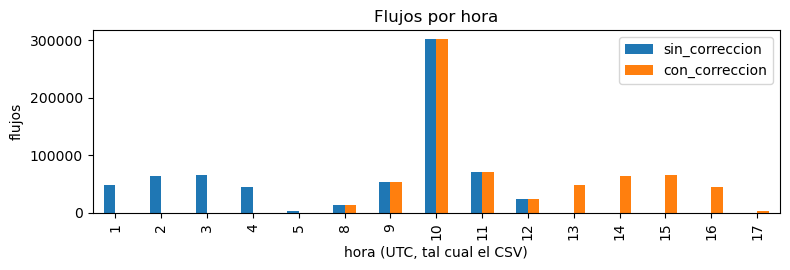

Pasos hacia atrás en el orden del fichero: 23.7% (si es > 0, el productor ordena por timestamp antes de reproducir)
Rango: 2017-07-05 08:42:00+00:00 -> 2017-07-05 17:10:00+00:00


,filas
label,
BENIGN,440031
DoS Hulk,231073
DoS GoldenEye,10293
DoS slowloris,5796
DoS Slowhttptest,5499
Heartbleed,11


In [4]:
def hours(col): return pd.to_datetime(df[col], unit="ms", utc=True).dt.hour.value_counts().sort_index()
hist = pd.DataFrame({"sin_correccion": hours("timestamp_ms_plain"), "con_correccion": hours("timestamp_ms")}).fillna(0).astype(int)
display(hist.T)

fig, ax = plt.subplots(figsize=(8, 2.8))
hist.plot.bar(ax=ax); ax.set_xlabel("hora (UTC, tal cual el CSV)"); ax.set_ylabel("flujos"); ax.set_title("Flujos por hora")
plt.tight_layout(); plt.show()

desc_file = (df["timestamp_ms"].diff() < 0).mean()
print(f"Pasos hacia atrás en el orden del fichero: {desc_file:.1%} (si es > 0, el productor ordena por timestamp antes de reproducir)")
print("Rango:", pd.to_datetime(df.timestamp_ms.min(), unit='ms', utc=True), "->", pd.to_datetime(df.timestamp_ms.max(), unit='ms', utc=True))
df["label"].value_counts().to_frame("filas")

## 3. Limpieza

| Problema | Tratamiento | Dónde |
|---|---|---|
| `Infinity` en `Flow Bytes/s`, `Flow Packets/s` | Ya convertido a `NaN` al cargar | Sección 1 |
| `NaN` | Imputación por **mediana de train** dentro del pipeline | Sección 5 |
| Duplicados exactos | Se eliminan antes de dividir | Aquí |
| Clases con muy pocas filas | Se agrupan en `OTHER_ATTACK` | Aquí |
| Valores negativos (`Init_Win_bytes` = -1) | Se mantienen: -1 significa "sin ventana" y es informativo | - |

In [5]:
print("Nulos por feature (solo las que tienen):")
nulls = df[FEATURE_FIELDS].isna().sum(); display(nulls[nulls > 0].to_frame("nulos"))

n0 = len(df)
df = df.dropna(subset=["label", "timestamp_ms"])
if DROP_DUPLICATES:
    df = df.drop_duplicates(subset=FEATURE_FIELDS + ["label"])
print(f"Filas: {n0} -> {len(df)} tras limpieza ({n0 - len(df)} eliminadas)")

counts = df["label"].value_counts()
rare = [c for c, n in counts.items() if c != "BENIGN" and n < RARE_THRESHOLD]
if rare:
    print(f"Clases con < {RARE_THRESHOLD} filas agrupadas en OTHER_ATTACK: {rare}")
    df["label"] = df["label"].where(~df["label"].isin(rare), "OTHER_ATTACK")
df["label"].value_counts().to_frame("filas")

Nulos por feature (solo las que tienen):


,nulos
flow_byts_s,1297
flow_pkts_s,1297


Filas: 692703 -> 602318 tras limpieza (90385 eliminadas)
Clases con < 100 filas agrupadas en OTHER_ATTACK: ['Heartbleed']


,filas
label,
BENIGN,408568
DoS Hulk,172844
DoS GoldenEye,10286
DoS slowloris,5381
DoS Slowhttptest,5228
OTHER_ATTACK,11


## 4. Split cronológico por clase con embargo

**Por qué no aleatorio:** flujos vecinos en el tiempo son casi idénticos (un ataque DoS genera miles seguidos). Un split aleatorio pone hermanos en train y test y da métricas irreales.

**Por qué no bloques globales de igual nº de filas** (primera versión de este notebook): en Wednesday cada ataque es **un único episodio** de 13 a 23 minutos, y el flujo es muy denso (Hulk: ~200 flujos/s). Un bloque de 30 000 filas dura ~2-3 minutos en pleno ataque y el embargo se lo come entero: el test salía **sin ningún ataque** y las métricas no valían.

**Solución:** el corte se hace **dentro de cada clase**, en orden cronológico. Cada clase se divide en bloques contiguos con el patrón `train, train, train, val, test` (60/20/20) y se aplica un **embargo** alrededor de cada corte. Así *todas* las clases con suficientes filas están en train, val y test.

| Decisión | Valor | Motivo |
|---|---|---|
| Bloques por clase | 20 si cada bloque dura ≥ 5 min (el tráfico benigno); 5 si no (cada ataque) | Un episodio de 15 min no admite 20 bloques |
| Embargo | ±60 s, es decir el minuto del corte | El timestamp del CSV tiene resolución de 1 minuto: no se pueden separar filas del mismo minuto |
| Clases con < 500 filas | Enteras a train | No hay filas para evaluar; se avisa |

**Limitación que hay que citar en la memoria:** dentro de un episodio, train y test provienen de la misma ejecución del ataque (minutos contiguos). Es optimista. La prueba de generalización real es el **test externo con CSE-CIC-IDS2018**.

> **Frase para memorizar:** *se corta dentro de cada clase para que cada ataque esté en train y en test; el embargo evita que el minuto de la frontera se cuele de un lado al otro.*

In [6]:
df = df.sort_values("timestamp_ms", kind="stable").reset_index(drop=True) if TIME_ORDER == "timestamp" else df.reset_index(drop=True)
n = len(df)
t_all = df["timestamp_ms"].to_numpy() if TIME_ORDER == "timestamp" else np.arange(n)
embargo = EMBARGO_S * 1000 if TIME_ORDER == "timestamp" else EMBARGO_ROWS
unit_s = 1000 if TIME_ORDER == "timestamp" else None

assert N_BLOCKS % len(BLOCK_PATTERN) == 0
split = np.full(n, "", dtype=object)
keep = np.ones(n, dtype=bool)
blocks_used, summary = {}, []

for cls, idx in df.groupby("label").indices.items():
    idx = np.sort(idx); m = len(idx); tc = t_all[idx]
    dur_min = (tc[-1] - tc[0]) / 1000 / 60 if unit_s else float("nan")
    if m < MIN_ROWS_TO_SPLIT:
        split[idx] = "train"; blocks_used[cls] = 0
        summary.append((cls, m, round(dur_min, 1), 0, 0)); continue
    nb = N_BLOCKS if (unit_s is None or dur_min * 60 / N_BLOCKS >= MIN_BLOCK_S) else len(BLOCK_PATTERN)
    blocks_used[cls] = nb
    blk = np.minimum(np.arange(m) * nb // m, nb - 1)
    sp = np.array([BLOCK_PATTERN[b % len(BLOCK_PATTERN)] for b in blk], dtype=object)
    split[idx] = sp
    cuts = np.flatnonzero((blk[1:] != blk[:-1]) & (sp[1:] != sp[:-1])) + 1
    dropped = np.zeros(m, dtype=bool)
    for j in cuts:                     # se descartan las filas de ESTA clase a menos de EMBARGO del corte
        lo = np.searchsorted(tc, tc[j] - embargo, side="right")
        hi = np.searchsorted(tc, tc[j] + embargo, side="left")
        dropped[lo:hi] = True
    keep[idx[dropped]] = False
    summary.append((cls, m, round(dur_min, 1), nb, int(dropped.sum())))

df["split"] = split
print(f"Filas descartadas por embargo: {(~keep).sum()} de {n} ({(~keep).mean():.1%})")
display(pd.DataFrame(summary, columns=["clase", "filas", "duracion_min", "bloques", "filas_embargo"]).set_index("clase"))
df = df[keep].reset_index(drop=True)

tab = pd.crosstab(df["label"], df["split"]).reindex(columns=["train", "val", "test"], fill_value=0)
display(tab)

# Comprobaciones: un test sin ataques (o una clase sin test) hace que las métricas no valgan
assert (df.loc[df.split == "test", "label"] != "BENIGN").any(), "ERROR: el test no tiene ningun ataque; revisar el split"
assert (df.loc[df.split == "val", "label"] != "BENIGN").any(), "ERROR: la validacion no tiene ningun ataque"
classes_train = set(df.loc[df.split == "train", "label"])
unseen = sorted(set(df.loc[df.split == "test", "label"]) - classes_train)
if unseen: print("AVISO: clases en test que no están en train (el modelo nunca podrá acertarlas):", unseen)
for c in tab.index:
    if tab.loc[c, "train"] == 0 or tab.loc[c, "test"] < 100 or tab.loc[c, "val"] < 100:
        print(f"AVISO: la clase {c!r} tiene muy pocas filas en algún split ({tab.loc[c].to_dict()}) -> métricas poco fiables")

Filas descartadas por embargo: 36246 de 602318 (6.0%)


,filas,duracion_min,bloques,filas_embargo
clase,,,,
BENIGN,408568,508.0,20,10650
DoS GoldenEye,10286,9.0,5,3346
DoS Hulk,172844,24.0,5,17648
DoS Slowhttptest,5228,22.0,5,1858
DoS slowloris,5381,324.0,20,2744
OTHER_ATTACK,11,20.0,0,0


split,train,val,test
label,,,
BENIGN,241749,75998,80171
DoS GoldenEye,6164,0,776
DoS Hulk,94008,27720,33468
DoS Slowhttptest,3133,161,76
DoS slowloris,2156,106,375
OTHER_ATTACK,11,0,0


AVISO: la clase 'DoS GoldenEye' tiene muy pocas filas en algún split ({'train': 6164, 'val': 0, 'test': 776}) -> métricas poco fiables
AVISO: la clase 'DoS Slowhttptest' tiene muy pocas filas en algún split ({'train': 3133, 'val': 161, 'test': 76}) -> métricas poco fiables
AVISO: la clase 'OTHER_ATTACK' tiene muy pocas filas en algún split ({'train': 11, 'val': 0, 'test': 0}) -> métricas poco fiables


## 5. Entrenamiento

Random Forest con `class_weight="balanced_subsample"` (el tráfico benigno domina) y **imputación dentro del pipeline**, así la mediana se calcula solo con train. `max_depth` y `min_samples_leaf` acotan el tamaño del modelo, que Flink tendrá que cargar en cada worker.

In [7]:
def xy(name):
    d = df[df.split == name]
    return d[FEATURE_FIELDS].to_numpy(dtype=float), d["label"].to_numpy()

X_train, y_train = xy("train"); X_val, y_val = xy("val"); X_test, y_test = xy("test")
if len(X_train) > MAX_TRAIN_ROWS:
    idx = np.random.default_rng(SEED).choice(len(X_train), MAX_TRAIN_ROWS, replace=False)
    X_train, y_train = X_train[idx], y_train[idx]
print("train/val/test:", len(X_train), len(X_val), len(X_test))

model = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("rf", RandomForestClassifier(n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH, min_samples_leaf=MIN_LEAF,
                                  class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)),
])
t0 = time.time(); model.fit(X_train, y_train); print(f"Entrenado en {time.time()-t0:.1f} s")
print("F1 macro en validación:", round(precision_recall_fscore_support(y_val, model.predict(X_val), average="macro", zero_division=0)[2], 4))

train/val/test: 300000 103985 114866
Entrenado en 18.0 s
F1 macro en validación: 0.8577


## 6. Evaluación en test

Se mira **una sola vez** sobre test (val sirve para tocar hiperparámetros). Dos vistas: multiclase (qué tipo de ataque) y binaria (¿es ataque?), que es la que dispara la alerta en Grafana.

| Métrica | Pregunta que responde | Qué vigilar en IDS |
|---|---|---|
| Precision | De lo que alerté, ¿cuánto era ataque real? | Falsos positivos = fatiga de alertas |
| Recall | De los ataques reales, ¿cuántos detecté? | Falsos negativos = ataques que pasan |
| F1 | Equilibrio entre ambas | Resumen por clase |
| FPR | ¿Cuánto tráfico benigno marqué como ataque? | Debe ser muy bajo |

                  precision    recall  f1-score   support

          BENIGN     0.9807    0.9993    0.9899     80171
   DoS GoldenEye     0.8416    1.0000    0.9140       776
        DoS Hulk     0.9986    0.9517    0.9746     33468
DoS Slowhttptest     0.8833    0.6974    0.7794        76
   DoS slowloris     0.9829    0.7653    0.8606       375

        accuracy                         0.9845    114866
       macro avg     0.9374    0.8828    0.9037    114866
    weighted avg     0.9849    0.9845    0.9844    114866



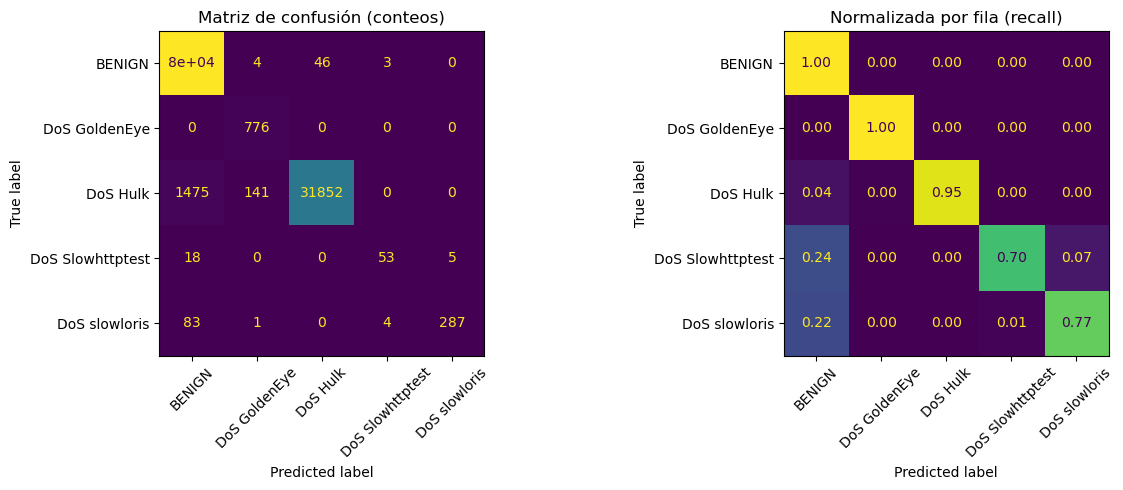

,vista binaria (ataque vs benigno)
precision,0.998402
recall,0.954576
f1,0.975997
fpr,0.000661
tp,33119.000000
fp,53.000000
fn,1576.000000
tn,80118.000000


In [8]:
pred = model.predict(X_test)
labels = sorted(set(y_test) | set(pred))
print(classification_report(y_test, pred, labels=labels, digits=4, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=labels, ax=axes[0], xticks_rotation=45, colorbar=False)
axes[0].set_title("Matriz de confusión (conteos)")
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=labels, ax=axes[1], xticks_rotation=45,
                                        normalize="true", values_format=".2f", colorbar=False)
axes[1].set_title("Normalizada por fila (recall)")
plt.tight_layout(); plt.savefig(REPORTS_DIR / f"{MODEL_NAME}_confusion.png", dpi=150); plt.show()

# Vista binaria: ataque vs benigno
yb, pb = (y_test != "BENIGN"), (pred != "BENIGN")
tn, fp, fn, tp = confusion_matrix(yb, pb, labels=[False, True]).ravel()
p, r, f1, _ = precision_recall_fscore_support(yb, pb, average="binary", zero_division=0)
binary = {"precision": p, "recall": r, "f1": f1, "fpr": fp / max(1, fp + tn), "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn)}
pd.Series(binary).to_frame("vista binaria (ataque vs benigno)")

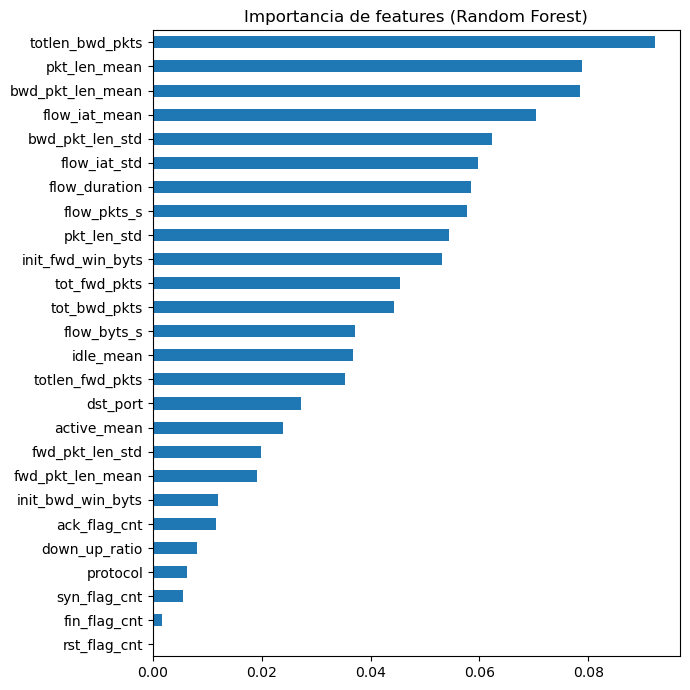

,importancia
totlen_bwd_pkts,0.092229
pkt_len_mean,0.078871
bwd_pkt_len_mean,0.078509
flow_iat_mean,0.070477
bwd_pkt_len_std,0.062250
flow_iat_std,0.059692
flow_duration,0.058433
flow_pkts_s,0.057738
pkt_len_std,0.054337
init_fwd_win_byts,0.053118


In [9]:
imp = pd.Series(model.named_steps["rf"].feature_importances_, index=FEATURE_FIELDS).sort_values()
fig, ax = plt.subplots(figsize=(7, 7)); imp.plot.barh(ax=ax); ax.set_title("Importancia de features (Random Forest)")
plt.tight_layout(); plt.savefig(REPORTS_DIR / f"{MODEL_NAME}_importances.png", dpi=150); plt.show()
imp.sort_values(ascending=False).head(10).to_frame("importancia")

## 7. Latencia y throughput de inferencia

Dato clave para la dimensión de **rendimiento**. Se mide con `n_jobs=1` porque en eventos sueltos la paralelización añade más overhead que ahorro. Es una medida del modelo aislado: la latencia extremo a extremo (Kafka → Flink → salida) se mide después con el timestamp del registro de Kafka.

In [10]:
model.named_steps["rf"].set_params(n_jobs=1)
sample = X_test[:N_LATENCY]
model.predict(sample[:5])  # calentamiento
lat = []
for i in range(len(sample)):
    t0 = time.perf_counter(); model.predict(sample[i:i+1]); lat.append((time.perf_counter() - t0) * 1000)
lat = np.array(lat)

big = np.tile(X_test, (10_000 // len(X_test) + 1, 1))[:10_000]  # 10k eventos para medir throughput
t0 = time.perf_counter(); model.predict(big); batch_s = time.perf_counter() - t0

latency = {"single_p50_ms": float(np.percentile(lat, 50)), "single_p95_ms": float(np.percentile(lat, 95)),
           "single_p99_ms": float(np.percentile(lat, 99)), "batch_10k_events_per_s": float(len(big) / batch_s)}
pd.Series(latency).round(3).to_frame("valor")

,valor
single_p50_ms,8.777
single_p95_ms,14.422
single_p99_ms,15.347
batch_10k_events_per_s,203812.932


## 8. Exportación del modelo

Se guardan **tres ficheros**:

| Fichero | Para qué | Quién lo usa |
|---|---|---|
| `hotpath_rf_v1.onnx` | Modelo portable | **Flink** (vía `onnxruntime`) |
| `hotpath_rf_v1.json` | Orden exacto de features, clases, métricas, versiones | Flink (valida el orden) y la memoria |
| `hotpath_rf_v1.joblib` | Reutilizar el modelo en este notebook | Solo tú, en tu entorno |

**¿Por qué ONNX y no solo joblib?** Un `.joblib` es un *pickle*: solo se carga con las mismas versiones de NumPy y scikit-learn con las que se creó. PyFlink 1.20 exige NumPy 1.x y tu Python local trae NumPy 2.x, así que el `.joblib` **falla dentro del contenedor** (`No module named 'numpy._core'`, comprobado). ONNX es un formato neutro y `onnxruntime` es también más rápido que scikit-learn para un evento suelto.

**El orden de features importa:** el modelo recibe un array sin nombres, así que si Flink pasa las columnas en otro orden predice basura sin dar error.

> **Frase para memorizar:** *el pickle viaja con sus versiones, ONNX viaja solo.*

In [11]:
model_path = MODELS_DIR / f"{MODEL_NAME}.joblib"
onnx_path  = MODELS_DIR / f"{MODEL_NAME}.onnx"
joblib.dump(model, model_path, compress=3)

# --- ONNX: entrada float32 [n, 26]; salidas: etiqueta y probabilidades (sin ZipMap) ---
onx = convert_sklearn(
    model, initial_types=[("input", FloatTensorType([None, len(FEATURE_FIELDS)]))],
    options={RandomForestClassifier: {"zipmap": False}},
    target_opset={"": 17, "ai.onnx.ml": 3},
)
onnx_path.write_bytes(onx.SerializeToString())

# Paridad ONNX vs scikit-learn sobre test
sess = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
onnx_labels = sess.run(None, {"input": X_test.astype(np.float32)})[0]
parity = float((onnx_labels == model.predict(X_test)).mean())
print(f"Paridad ONNX vs sklearn en test: {parity:.4%}")
assert parity > 0.999, "ONNX no reproduce las predicciones de sklearn: revisar la conversión"

meta = {
    "model_name": MODEL_NAME, "schema_version": SCHEMA_VERSION,
    "trained_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "onnx_input_name": "input", "onnx_input_dtype": "float32",
    "feature_order": FEATURE_FIELDS, "classes": [str(c) for c in model.named_steps["rf"].classes_],
    "split": {"mode": "per_class_chronological", "order": TIME_ORDER, "n_blocks_max": N_BLOCKS, "blocks_by_class": blocks_used,
              "pattern": BLOCK_PATTERN, "min_block_s": MIN_BLOCK_S, "embargo_s": EMBARGO_S, "min_rows_to_split": MIN_ROWS_TO_SPLIT},
    "rows": {"train": int(len(X_train)), "val": int(len(X_val)), "test": int(len(X_test))},
    "binary_metrics_test": {k: (round(v, 6) if isinstance(v, float) else v) for k, v in binary.items()},
    "latency_sklearn": {k: round(v, 4) for k, v in latency.items()},
    "onnx_parity_test": round(parity, 6),
    "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__,
                 "numpy": np.__version__, "onnxruntime": ort.__version__},
    "source_csv": CSV_PATH.name,
}
(MODELS_DIR / f"{MODEL_NAME}.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")

reloaded = joblib.load(model_path)
assert (reloaded.predict(X_test[:2000]) == model.predict(X_test[:2000])).all()
print(f"ONNX: {onnx_path.stat().st_size/1e6:.1f} MB | joblib: {model_path.stat().st_size/1e6:.1f} MB | metadatos guardados | recarga OK")

Paridad ONNX vs sklearn en test: 100.0000%
ONNX: 3.8 MB | joblib: 1.9 MB | metadatos guardados | recarga OK


### Latencia con ONNX Runtime

Es la que cuenta para Flink, porque es el motor que cargará el UDF.

In [12]:
so = ort.SessionOptions(); so.intra_op_num_threads = 1
sess1 = ort.InferenceSession(str(onnx_path), so, providers=["CPUExecutionProvider"])
xs = X_test[:N_LATENCY].astype(np.float32)
sess1.run(None, {"input": xs[:5]})
lat_o = []
for i in range(len(xs)):
    t0 = time.perf_counter(); sess1.run(None, {"input": xs[i:i+1]}); lat_o.append((time.perf_counter() - t0) * 1000)
lat_o = np.array(lat_o)
latency_onnx = {"single_p50_ms": float(np.percentile(lat_o, 50)), "single_p95_ms": float(np.percentile(lat_o, 95)),
                "single_p99_ms": float(np.percentile(lat_o, 99))}
meta["latency_onnx"] = {k: round(v, 4) for k, v in latency_onnx.items()}
(MODELS_DIR / f"{MODEL_NAME}.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
pd.DataFrame({"sklearn": {k: latency[k] for k in latency_onnx}, "onnxruntime": latency_onnx}).round(3)

,sklearn,onnxruntime
single_p50_ms,8.777,0.029
single_p95_ms,14.422,0.043
single_p99_ms,15.347,0.059


## Siguientes pasos

1. Copiar `models/hotpath_rf_v1.onnx` y `.json` al volumen que monta Flink (ver `flink/README.md`).
2. Repetir la evaluación con un día de CSE-CIC-IDS2018 como **test externo** (requiere el mapeo de columnas 2018 en `schema_v1.py`).
3. Probar XGBoost o LightGBM si el Random Forest pesa demasiado; comparar F1 y latencia en una tabla para la memoria.

| Qué guardar para la memoria | Dónde está |
|---|---|
| Matriz de confusión | `reports/hotpath_rf_v1_confusion.png` |
| Importancia de features | `reports/hotpath_rf_v1_importances.png` |
| Métricas binarias, paridad ONNX y latencias | `models/hotpath_rf_v1.json` |
| Configuración del split | Sección 4 y el JSON |